# Predicting hotel booking cancellations

About a third of hotel bookings in this dataset are cancelled. If a hotel can tell which bookings are
likely to cancel, it can overbook more safely, follow up with guests, or ask for a deposit.

This notebook cleans the data, looks at what drives cancellations, and trains models that predict whether
a booking will be cancelled, **using only what the hotel knows when the booking is made**.

**Data:** 119,390 bookings from a city hotel and a resort hotel in Portugal, arriving between July 2015 and
August 2017. From Antonio, de Almeida and Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22,
41–49 ([doi:10.1016/j.dib.2018.11.022](https://doi.org/10.1016/j.dib.2018.11.022)).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.precision", 3)


def save(name):
    plt.tight_layout()
    plt.savefig(IMAGES / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 1. Load the data

In [2]:
raw = pd.read_csv("data/hotel_bookings.csv")
print(raw.shape)
raw.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01/07/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01/07/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02/07/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02/07/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03/07/2015


In [3]:
print(f"Cancellation rate: {raw['is_canceled'].mean():.1%}")
raw.isna().sum()[lambda s: s > 0]

Cancellation rate: 37.0%


children         4
country        488
agent        16340
company     112593
dtype: int64

## 2. Cleaning

- **Missing values.** `agent` and `company` are IDs and mostly empty, so they're dropped. A missing
  `children` count most likely means none, so it becomes 0. A missing `country` becomes "Unknown".
- **Bookings with no guests** (0 adults, children and babies) and **bookings with no nights** can't be real
  stays, so they're removed.
- **Prices.** One booking has a negative average daily rate and one is over €5,000 a night (the next
  highest is about €510), so both are removed as data errors.
- **Duplicates.** About 40,000 rows have at least one identical copy. The dataset has no booking ID, and
  these rows are mostly group and tour operator bookings, so they're likely real separate bookings made
  together (several rooms for one group). They're kept, because removing them would hide a big share of
  the cancellations. They are dealt with when splitting the data (section 4).

In [4]:
df = raw.drop(columns=["agent", "company"])
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")

no_guests = (df["adults"] + df["children"] + df["babies"]) == 0
no_nights = (df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0
bad_price = (df["adr"] < 0) | (df["adr"] > 1000)
print(f"No guests: {no_guests.sum()}, no nights: {no_nights.sum()}, bad price: {bad_price.sum()}")

df = df[~(no_guests | no_nights | bad_price)].reset_index(drop=True)
print(f"Rows left: {len(df):,}")

dup = df.duplicated(keep=False)
print(f"\nRows with an identical copy: {dup.sum():,}")
print(f"Cancelled: {df.loc[dup, 'is_canceled'].mean():.0%} of those, {df.loc[~dup, 'is_canceled'].mean():.0%} of the rest")
df.loc[dup, "market_segment"].value_counts(normalize=True).head(3).map("{:.0%}".format)

No guests: 180, no nights: 715, bad price: 2
Rows left: 118,563



Rows with an identical copy: 40,103
Cancelled: 58% of those, 26% of the rest


market_segment
Groups           42%
Offline TA/TO    30%
Online TA        21%
Name: proportion, dtype: str

## 3. What drives cancellations?

### Cancellation rate by hotel

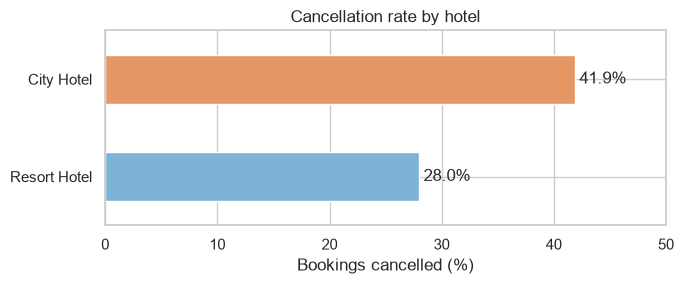

In [5]:
rate = df.groupby("hotel")["is_canceled"].mean().mul(100).sort_values()
ax = rate.plot.barh(color=["#7fb3d5", "#e59866"], figsize=(7, 3))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(xlabel="Bookings cancelled (%)", ylabel="", title="Cancellation rate by hotel", xlim=(0, 50))
save("cancellation_by_hotel")

The city hotel loses a noticeably bigger share of its bookings than the resort hotel.

### Meal plans

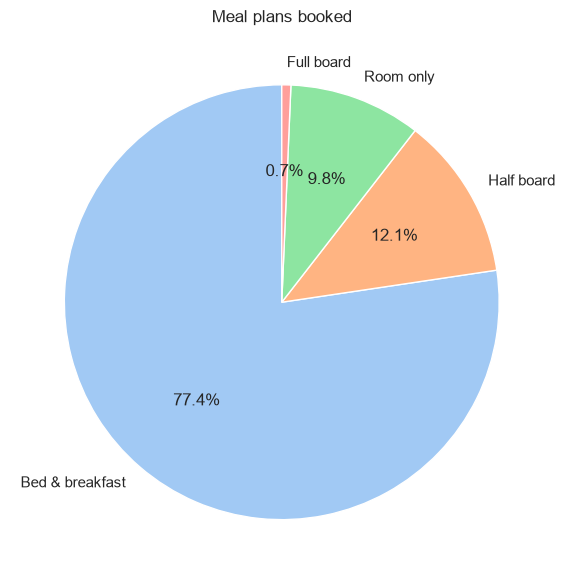

In [6]:
meals = df["meal"].replace({"Undefined": "SC"}).value_counts()
names = {"BB": "Bed & breakfast", "HB": "Half board", "SC": "Room only", "FB": "Full board"}
plt.figure(figsize=(6, 6))
plt.pie(meals, labels=[names.get(m, m) for m in meals.index], autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"))
plt.title("Meal plans booked")
save("meal_plans")

Bed and breakfast is by far the most popular plan. The dataset's documentation says "Undefined" and "SC"
both mean no meal package, so they're counted together as room only.

### Returning guests

In [7]:
returning = df["is_repeated_guest"].mean()
print(f"Returning guests: {df['is_repeated_guest'].sum():,} bookings ({returning:.1%})")
print(df.groupby("is_repeated_guest")["is_canceled"].mean().rename({0: "New", 1: "Returning"}).map("{:.1%}".format))

Returning guests: 3,498 bookings (3.0%)
is_repeated_guest
New          37.9%
Returning    15.7%
Name: is_canceled, dtype: str


Only a small share of bookings are from returning guests, and they cancel far less often than new guests.

### Room types

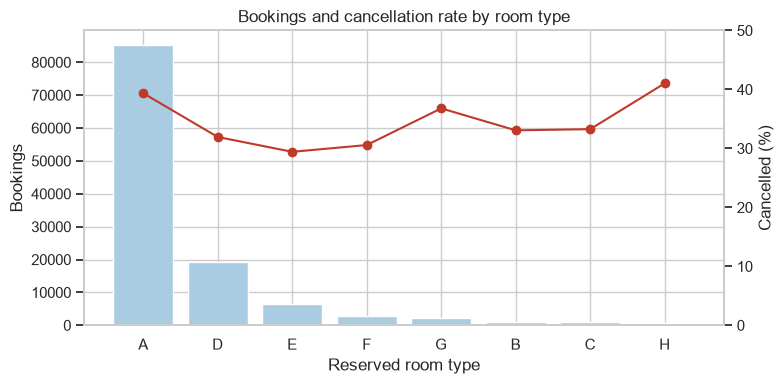

In [8]:
rooms = (df.groupby("reserved_room_type")["is_canceled"].agg(bookings="size", cancel_rate="mean")
           .query("bookings >= 100").sort_values("bookings", ascending=False))
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(rooms.index, rooms["bookings"], color="#a9cce3")
ax1.set(xlabel="Reserved room type", ylabel="Bookings", title="Bookings and cancellation rate by room type")
ax2 = ax1.twinx()
ax2.plot(rooms.index, rooms["cancel_rate"] * 100, color="#c0392b", marker="o")
ax2.set(ylabel="Cancelled (%)", ylim=(0, 50))
ax2.grid(False)
save("room_types")

Room type A dominates. Cancellation rates differ by room type, but much less than they do for the
factors below. (Room types with fewer than 100 bookings are left off the chart.)

### Deposits, lead time and market segment

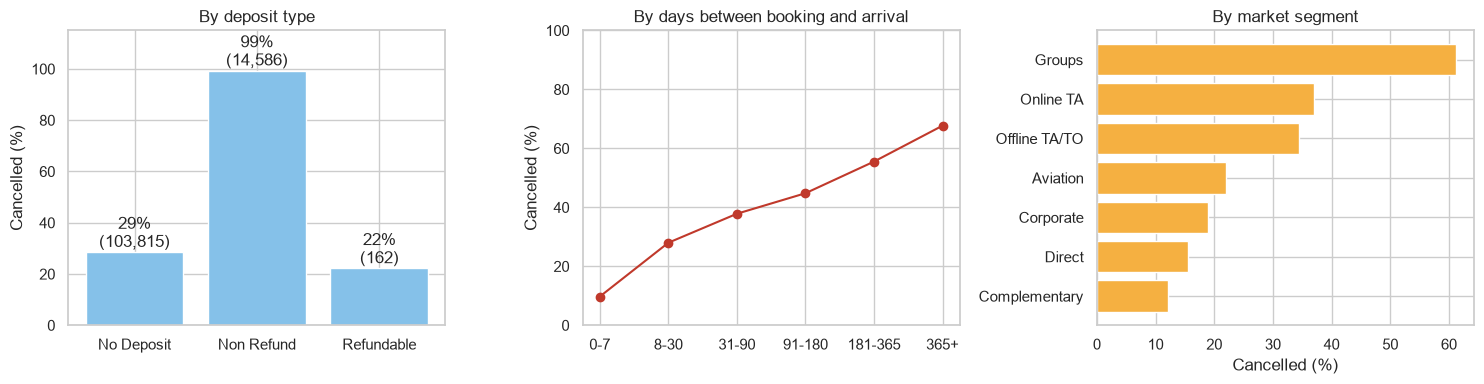

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

dep = df.groupby("deposit_type")["is_canceled"].agg(["mean", "size"])
axes[0].bar(dep.index, dep["mean"] * 100, color="#85c1e9")
for i, (m, n) in enumerate(zip(dep["mean"], dep["size"])):
    axes[0].text(i, m * 100 + 2, f"{m:.0%}\n({n:,})", ha="center")
axes[0].set(title="By deposit type", ylabel="Cancelled (%)", ylim=(0, 115))

bins = [-1, 7, 30, 90, 180, 365, 1000]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
lead = df.groupby(pd.cut(df["lead_time"], bins, labels=labels), observed=True)["is_canceled"].mean()
axes[1].plot(labels, lead * 100, marker="o", color="#c0392b")
axes[1].set(title="By days between booking and arrival", ylabel="Cancelled (%)", ylim=(0, 100))

seg = df.groupby("market_segment")["is_canceled"].mean().drop("Undefined", errors="ignore").sort_values()
axes[2].barh(seg.index, seg * 100, color="#f5b041")
axes[2].set(title="By market segment", xlabel="Cancelled (%)")
save("drivers")

- **Deposit type:** almost every non-refundable booking is cancelled, which is the opposite of what you'd
  expect. The dataset's authors don't explain it. A likely reason is that some bookings, such as tour
  operator blocks, are labelled non-refundable but released when they aren't used. Either way, the model
  will lean on it heavily, so it's worth questioning with the hotel before trusting it.
- **Lead time:** the further ahead a booking is made, the more likely it is to be cancelled.
- **Market segment:** group bookings cancel most often, then online travel agent bookings; direct and
  corporate bookings least.

### How the numeric features relate to cancellation

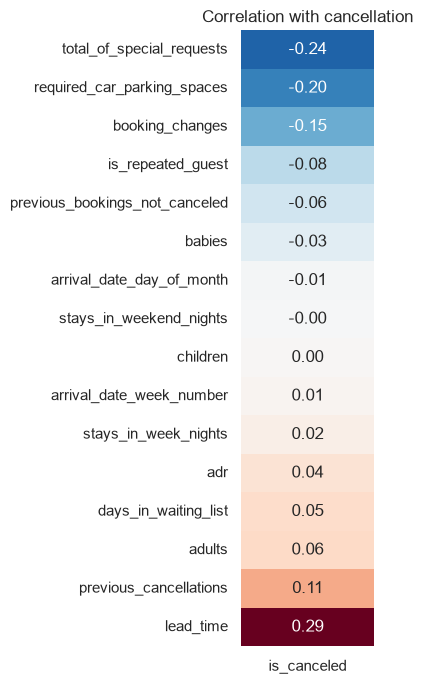

In [10]:
num = df.select_dtypes("number").drop(columns=["arrival_date_year"])
corr = num.corr()[["is_canceled"]].drop("is_canceled").sort_values("is_canceled")
plt.figure(figsize=(4, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Correlation with cancellation")
save("correlations")

## 4. Choosing features

A model is only useful if it can be used **at booking time**, so features the hotel only learns later are
left out:

| Left out | Why |
|---|---|
| `reservation_status`, `reservation_status_date` | Record the outcome itself (Canceled / Check-Out / No-Show) |
| `assigned_room_type` | Decided at check-in. Guests who cancel never get one assigned, so it leaks the answer |
| `booking_changes`, `days_in_waiting_list` | Keep changing until arrival |
| `country` | Bookings from Portugal cancel at a much higher rate than the rest (below). Nationality may only be confirmed at check-in for some bookings, so it's left out to be safe |
| `arrival_date_year` | A model used in the future will never see these years |

In [11]:
by_country = df.assign(origin=np.where(df["country"].eq("PRT"), "Portugal", "Elsewhere"))
by_country.groupby("origin")["is_canceled"].agg(bookings="size", cancel_rate="mean")

,bookings,cancel_rate
origin,,
Elsewhere,70621,0.236
Portugal,47942,0.573


In [12]:
LEAKY = ["reservation_status", "reservation_status_date", "assigned_room_type", "booking_changes",
         "days_in_waiting_list", "country", "arrival_date_year"]

y = df["is_canceled"]
X = df.drop(columns=["is_canceled", *LEAKY])
categorical = X.select_dtypes(exclude="number").columns.tolist()
print(f"{X.shape[1]} features, {len(categorical)} categorical: {categorical}")

22 features, 8 categorical: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']


**Splitting 70/30 without leaking duplicates.** If one copy of a group booking is in the training set and an
identical copy is in the test set, the model is effectively tested on data it has already seen. So identical
rows are given the same group ID and each group goes entirely into training or entirely into testing.

In [13]:
groups = pd.util.hash_pandas_object(df, index=False)
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print(f"Train: {len(X_train):,} rows, test: {len(X_test):,} rows")
print(f"Cancelled: {y_train.mean():.1%} of train, {y_test.mean():.1%} of test")

Train: 83,666 rows, test: 34,897 rows
Cancelled: 37.6% of train, 36.4% of test


Tree models don't need scaled features or one-hot encoding, so categories are just numbered. The encoder
sits inside a scikit-learn `Pipeline`, so it only ever learns from the training data.

In [14]:
def make_model(estimator):
    encode = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)],
        remainder="passthrough",
    )
    return Pipeline([("encode", encode), ("model", estimator)])


models = {
    "Decision tree (default)": DecisionTreeClassifier(random_state=SEED),
    "Decision tree (limited depth)": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
}

## 5. Training and evaluating

In [15]:
results, fitted = [], {}
for name, est in models.items():
    model = make_model(est).fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(results).set_index("model")
print(f"Always guessing 'not cancelled' would score {1 - y_test.mean():.1%} accuracy.")
results

Always guessing 'not cancelled' would score 63.6% accuracy.


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Decision tree (default),0.768,0.687,0.669,0.677,0.749
Decision tree (limited depth),0.812,0.824,0.615,0.704,0.861
Random forest,0.824,0.831,0.649,0.729,0.881


Accuracy alone is misleading here because most bookings aren't cancelled, so precision, recall, F1 and ROC
AUC are shown too. A default decision tree grows until it memorises the training data, which is why
limiting its depth gives better probability estimates (ROC AUC).

In [16]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_val_score(make_model(models["Random forest"]), X_train, y_train, groups=g_train,
                         cv=cv, scoring="f1", n_jobs=-1)
print(f"Random forest, 5-fold cross-validated F1 on the training set: {scores.mean():.3f} ± {scores.std():.3f}")

Random forest, 5-fold cross-validated F1 on the training set: 0.745 ± 0.009


Cross-validation gives a similar score with little spread, so the test result isn't down to a lucky split.

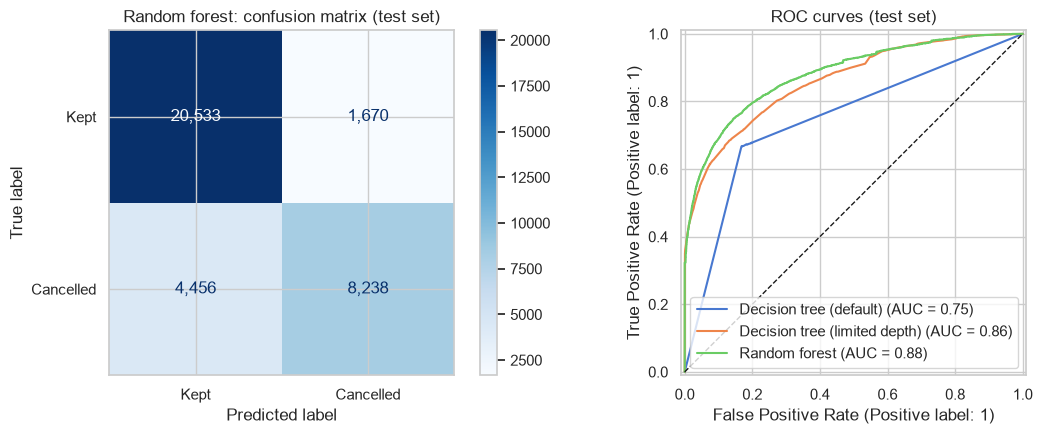

In [17]:
best = fitted["Random forest"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["Kept", "Cancelled"],
                                      cmap="Blues", values_format=",", ax=axes[0])
axes[0].set_title("Random forest: confusion matrix (test set)")
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curves (test set)")
save("evaluation")

## 6. What the model relies on

Built-in tree importances favour features with many distinct values, so this uses **permutation
importance** instead: shuffle one feature in the test set and measure how much the score drops.

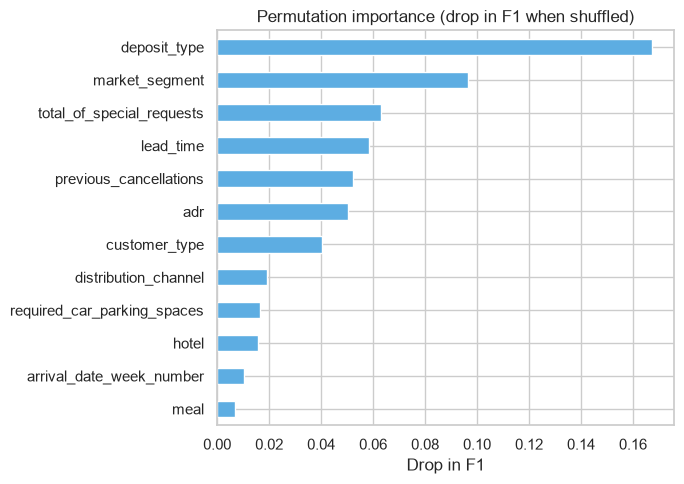

In [18]:
perm = permutation_importance(best, X_test, y_test, scoring="f1", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(12)
ax = imp.plot.barh(figsize=(7, 5), color="#5dade2")
ax.set(title="Permutation importance (drop in F1 when shuffled)", xlabel="Drop in F1")
save("feature_importance")

Deposit type and market segment matter most, followed by special requests, lead time and previous
cancellations, in line with the charts in section 3. Because
deposit type behaves so unusually, I'd want to understand it with the hotel before using this model for
real decisions.

## 7. Compared with my original coursework

My 2024 version trained a default decision tree and reached **84.5% accuracy**. The default tree here
scores lower, and that's expected, because the original:

- kept `assigned_room_type`, `country`, `booking_changes` and `arrival_date_year`, which the hotel only
  knows later or which won't generalise;
- split rows at random, so many test rows had an identical copy in the training set;
- scaled the features on the whole dataset before splitting it (which trees don't need anyway).

The cell below shows how much the random split alone flatters the same random forest.

In [19]:
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.3, stratify=y, random_state=SEED)
naive = make_model(models["Random forest"]).fit(X.iloc[idx_tr], y.iloc[idx_tr])
naive_pred = naive.predict(X.iloc[idx_te])
print(f"Random split:          accuracy {accuracy_score(y.iloc[idx_te], naive_pred):.3f}, F1 {f1_score(y.iloc[idx_te], naive_pred):.3f}")
print(f"Duplicate-aware split: accuracy {results.loc['Random forest', 'accuracy']:.3f}, F1 {results.loc['Random forest', 'f1']:.3f}")

Random split:          accuracy 0.857, F1 0.793
Duplicate-aware split: accuracy 0.824, F1 0.729


The scores in section 5 are a more honest estimate of how well cancellations can be predicted when a new
booking comes in.

## 8. Limitations and next steps

- Two hotels in Portugal between 2015 and 2017; patterns may be different elsewhere or today.
- The deposit type pattern needs explaining before the model can be trusted.
- Next: tune the random forest or try gradient boosting, pick a decision threshold based on the cost of
  overbooking versus an empty room, and check whether the model holds up on the most recent months
  (a time-based split).